# KErSe2: observations → quantum Hamiltonian → independent physical discrimination

## 1. Problem
Measured neutron peaks encode transition energies and quantum matrix elements. We recover six crystal-field coefficients plus nine spectral nuisance quantities in each of two competing anisotropy branches. Neither fitted Hamiltonian is known ground truth. Independent directional magnetization tests which neutron-consistent branch is physically appropriate. The real-data benchmark keeps all 540 neutron samples and all finite author-provided 0.5 K field/moment pairs.

This notebook actively executes the complete selected author method: same-data 17-parameter Voigt fit, width regression, seven-variable warmup, and two fifteen-variable native Nelder–Mead refinements. The independently validated extended maxfev=30000 budget converges; the historical default3000 protocol is a labeled budget-sensitivity comparison.

In [1]:
from pathlib import Path
import os, sys, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import figures, metrics
from src.physics_model import gtensor
data=load_data(ROOT/'data/raw_data.npz')
print('Observed neutron shape:',data['intensity'].shape,'; fit samples:',data['fit_mask'].sum(axis=1))
print('Independent magnetization samples:',len(data['field_ab']),len(data['field_c']))


Observed neutron shape: (3, 180) ; fit samples: [ 59 115 115]
Independent magnetization samples: 215 272


## 2. Data and reference roles
The author supplied processed real HYSPEC powder cuts at 1.8, 15 and 100 K, with incident energy 9 meV and Q integration 1.25–1.9 inverse angstrom. The low-temperature filename says 1p6K; the acquisition/source analysis uses 1.8 K. Reported errors are retained; they do not calibrate systematic background and broadening discrepancy. Fixed masks exclude elastic scattering, featureless edges and low-temperature negative transfer according to the published analysis.

**Observation:** neutron intensity/error versus energy and independent directional magnetization. **Unknown target:** two six-coefficient Hamiltonians and their nuisance parameters, including active inferred width coefficients. **GT:** no independently known Hamiltonian or complete true spectrum exists. **Reference:** separately executed original author software on exactly these bundled measurements, frozen before the local implementation. Historical paper and default-budget values are context, never substituted for fresh results.

## 3. Physics
For J=15/2, explicit real Stevens operators give

$$
H=\sum_{(l,m)\in\{(2,0),(4,0),(4,3),(6,0),(6,3),(6,6)\}} B_{lm}O_{lm}.
$$

The six B values are meV and the operators dimensionless. Ladder elements are square roots of (J−m)(J+m+1); Jx and Jy are the symmetric/antisymmetric ladder combinations and Jz is diagonal m. For self-contained operator definitions, let Z=Jz, P the raising matrix, Q its transpose, X=J(J+1), I the identity, S=P^3+Q^3 and A=11Z^3-(3X+59)Z. Ordinary products below are matrix products:
+
+$$
+\begin{aligned}
+O_{20}&=3Z^2-XI,\\
+O_{40}&=35Z^4-(30X-25)Z^2+(3X^2-6X)I,\\
+O_{43}&=(SZ+ZS)/4,\\
+O_{60}&=231Z^6-(315X-735)Z^4+(105X^2-525X+294)Z^2+(-5X^3+40X^2-60X)I,\\
+O_{63}&=(SA+AS)/4,\qquad O_{66}=(P^6+Q^6)/2.
+\end{aligned}
+$$
+
+The implementation builds every term directly. Eigenvalues are relative to the ground state, and eigenvectors determine the neutron matrix elements.

$$
\widehat I_T(e)=s\sum_{i:p_i>0.001}\sum_j p_i\sum_{a=x,y,z}|\langle i|J_a|j\rangle|^2 V(e(1+T\eta)-d-E_j+E_i;\,a(E_j-E_i)+b,\gamma_T)+c_T.
$$

Here p is the normalized Boltzmann population with k=0.0861733 meV/K; s is intensity prefactor, d the energy offset, eta the axis-expansion coefficient, gamma the temperature-specific Lorentz FWHM, c the temperature-specific constant background, and a/b the fitted Gaussian-width slope/intercept. V is a unit-area Voigt profile, evaluated explicitly using the Faddeeva function:

$$
V(u;\alpha,\gamma)=\frac{\Re w((u+\mathrm{i}\gamma/2)/(\sigma\sqrt2))}{\sigma\sqrt{2\pi}},\qquad \sigma=\alpha/(2\sqrt{2\ln2}).
$$

This source empirical response is valid only on the measured energy domain. Linear width extrapolation is negative at unmeasured high levels; the reflection identity w(−z)=2 exp(−z²)−w(z) bounds the signed-width correction below float64 underflow on every bound observation. Actual visible peak widths and all predicted bound intensities are positive. This does not establish a physical high-energy calibration.

## 4. Method: active inverse reconstruction
Estimate five Voigt peaks on all low-temperature observations, then regress the four inelastic Gaussian widths. Fit both published coarse hypotheses by the selected three-stage native Nelder–Mead workflow. The two coarse guesses are initialization, not calibration or truth. The objective uses all 289 fixed included observations:

$$
L(q)=\sum_{t,n:M_{tn}=1}\left(\frac{\widehat I_t(e_{tn};q)-I_{tn}}{u_{tn}}\right)^2.
$$

I denotes measured intensity, u its reported error, M the fixed inclusion mask and q the fifteen physical/nuisance parameters. There is no regularizer, noise inflation or amplitude fitting to magnetic data. The following cell runs every selected reconstruction stage from raw observations; it reads no checkpoint, fitted reference, or cached reconstruction.

In [2]:
prediction,diagnostics,runtime=run(ROOT)
print('Fresh complete local CPU reconstruction seconds:',runtime)
print(json.dumps(diagnostics['stages'],indent=2))
print('Active inferred Gaussian width [a,b]:',prediction['resolution_coefficients'])
print('Independent magnetic branch evidence:',diagnostics['selection'])
print('Selected row:',prediction['selected_model'])


Fresh complete local CPU reconstruction seconds: 211.59693690005224
[
  {
    "success": true,
    "status": 0,
    "nfev": 1243,
    "loss": 19667.554205966146,
    "message": "Optimization terminated successfully."
  },
  {
    "success": true,
    "status": 0,
    "nfev": 3702,
    "loss": 16710.585251101544,
    "message": "Optimization terminated successfully."
  },
  {
    "success": true,
    "status": 0,
    "nfev": 5494,
    "loss": 15535.070138658511,
    "message": "Optimization terminated successfully."
  }
]
Active inferred Gaussian width [a,b]: [[-0.0249575   0.36262711]]
Independent magnetic branch evidence: {'observed_moment_1T': [5.292504548058218, 2.441947025238985], 'model_contrast_1T': [1.5680144694474003, -3.984599497566471]}
Selected row: [0]


## 5. Results: real observations, reconstruction and scientific comparisons
Solid curves are freshly computed by local explicit mathematics. Dashed original curves come from the independent upstream execution, not paper caches. Initial coarse hypotheses and default-budget results are explicitly identified. Both competing branches and all three temperatures are retained. The original ground-doublet g-tensor comparison is also actively computed: for the two rounded ground states v1,v2, row a is 2g[Re?v1|Ja|v2?, Im?v1|Ja|v2?, ?v1|Ja|v1?], with the original absolute-z-diagonal convention. Tensor row norms give physical axis responses; signs/basis within a degenerate doublet are gauge dependent. Current source multiplies by known gJ=1.2. The paper reports historical easy-plane g values 6.0 and 4.9, whereas this current-source fit gives physical axis values about 7.175 and 5.846. Independent infinitesimal-field Zeeman splitting confirms the latter physical normalization. The near factor-1.2 relationship is a documented report/definition discrepancy, not proof of a historical software error; no constant is changed to force agreement. Residual plots show remaining systematic disagreement, not merely agreement with a method reference.

The source Model2 plotting cell accidentally borrowed Model1's thermal expansion although its objective used its own. Fresh plots consistently use each model's own coefficient. The actual code uses three constant backgrounds; the paper describes linear backgrounds. The source energy-axis remapping is retained, rather than silently replacing it with the paper's first-order transition formula. The independent magnetic data are the author's 0.5 K repository measurements; the paper's displayed bulk comparison includes a separate 2 K condition.

Fresh ground-doublet g tensors (dimensionless): [[[ 7.17534764  0.          0.        ]
  [ 0.         -7.17534764  0.        ]
  [ 0.          0.          5.84610627]]

 [[ 0.          0.          0.        ]
  [ 0.          0.          0.        ]
  [-0.78471095  0.         11.60802158]]]
Original current-code g tensors: [[[ 7.17534764  0.          0.        ]
  [ 0.         -7.17534764  0.        ]
  [ 0.          0.          5.84610627]]

 [[ 0.          0.          0.        ]
  [ 0.          0.          0.        ]
  [-0.78471095  0.         11.60802158]]]
Physical axis g values (row norms): [[ 7.17534764  7.17534764  5.84610627]
 [ 0.          0.         11.63451487]]
g tensor max absolute upstream difference: 0.0
[
  {
    "model": 0,
    "temperature": 1.8,
    "nfit": 59,
    "nrmse": 0.02680480098625021,
    "ncc": 0.9962300920147804,
    "chi2": 5875.270736873178
  },
  {
    "model": 0,
    "temperature": 15.0,
    "nfit": 115,
    "nrmse": 0.02354987818332444,
    "ncc": 

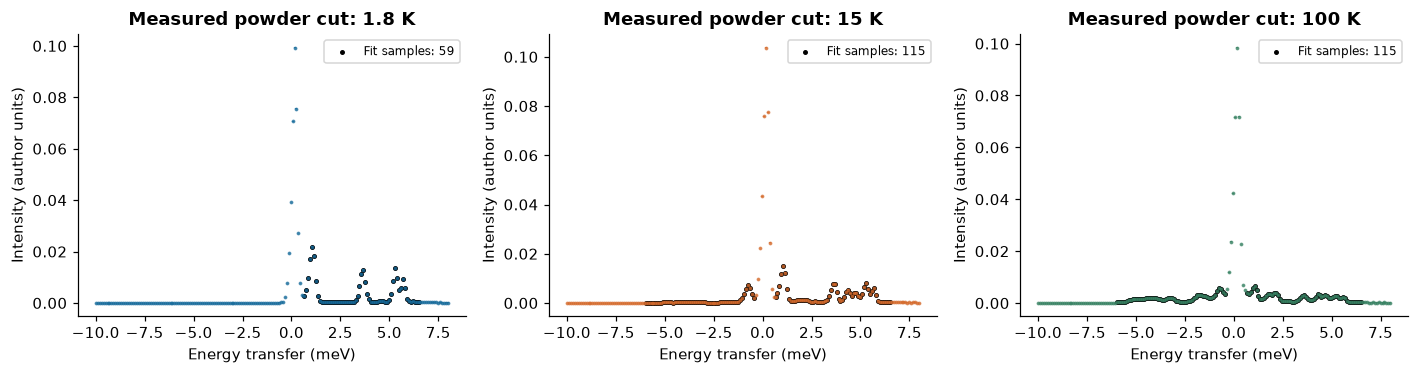

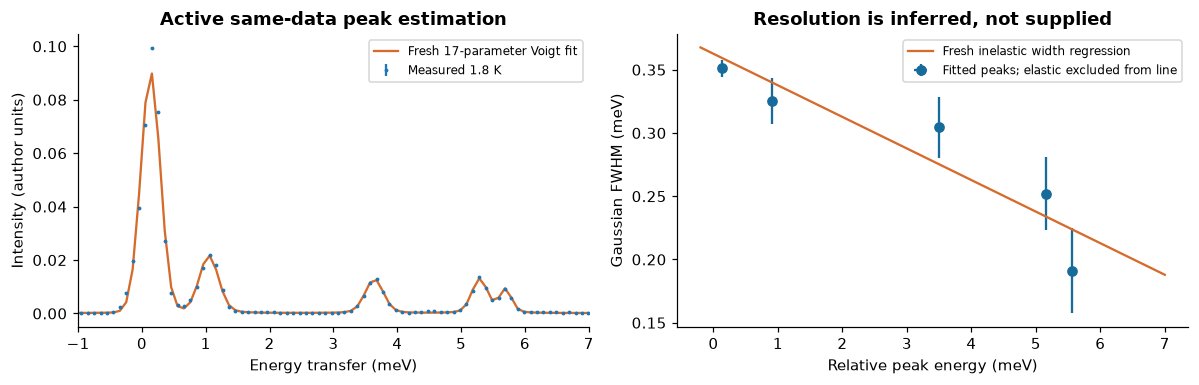

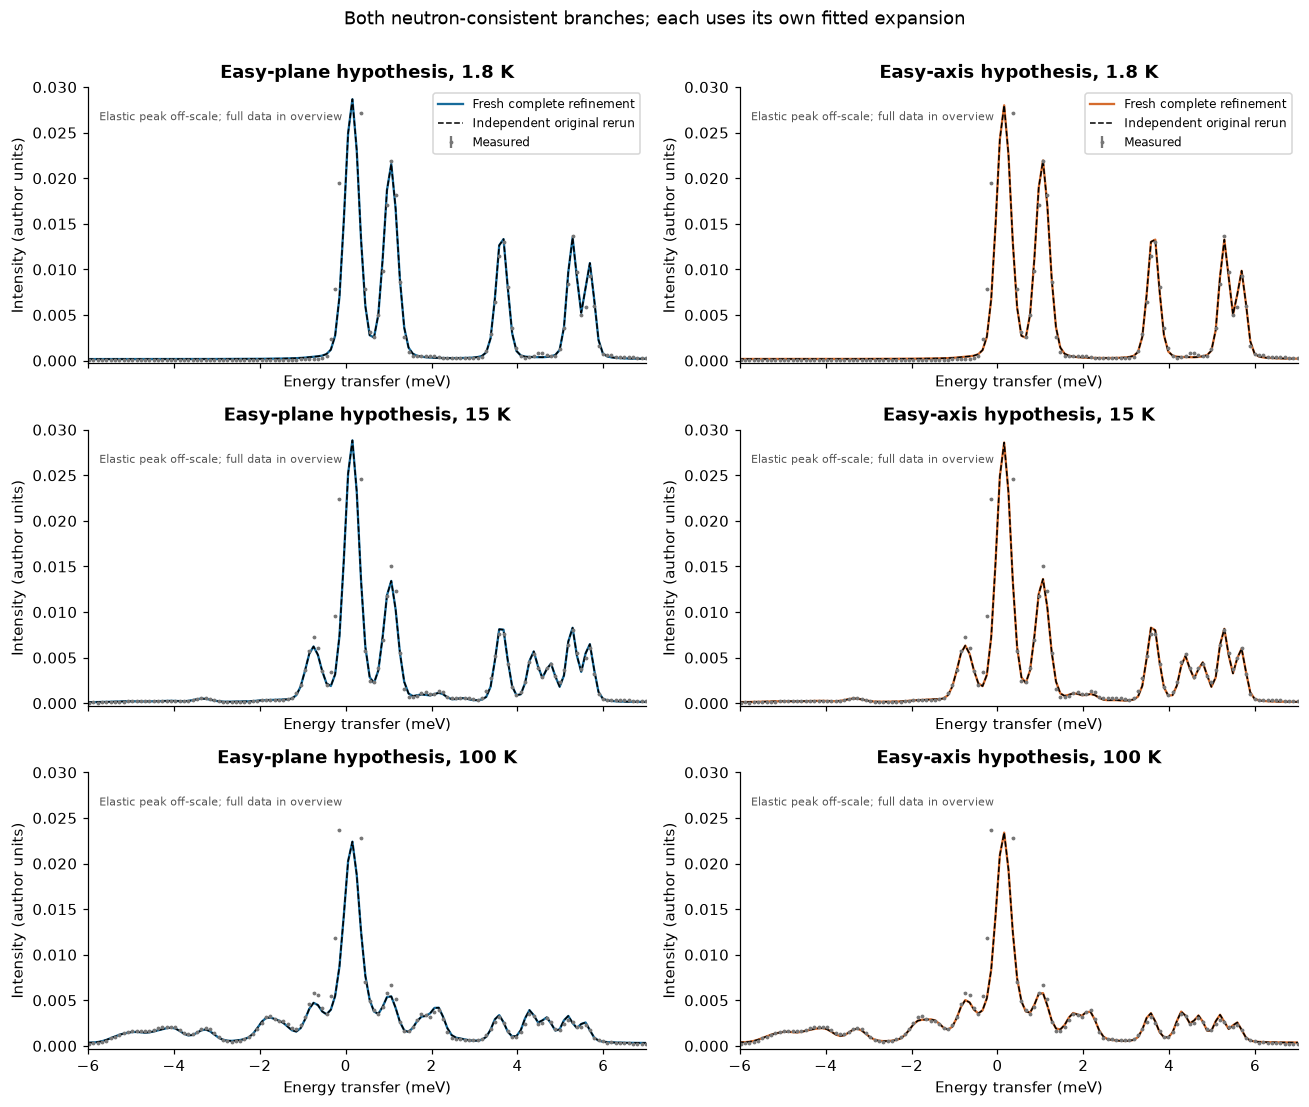

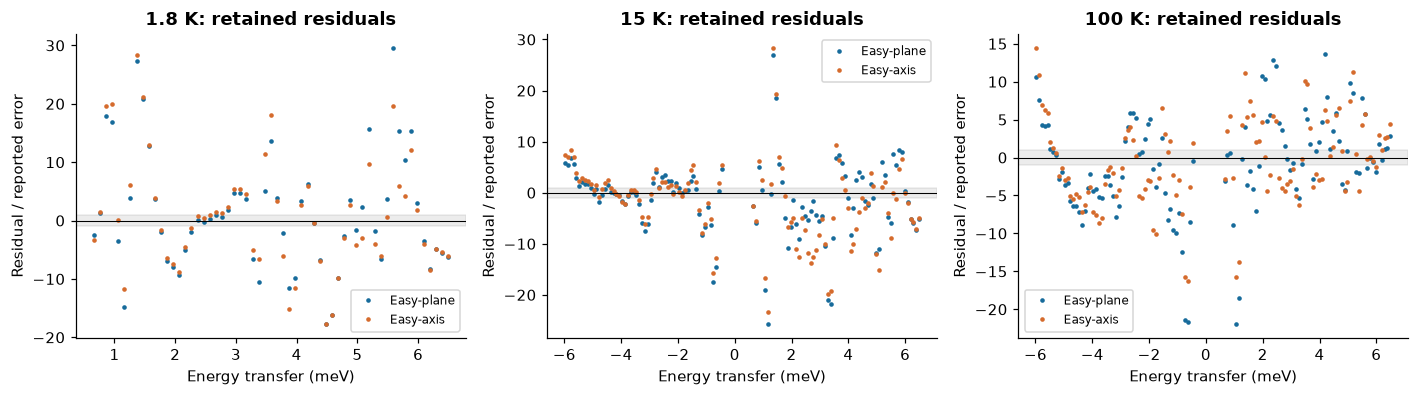

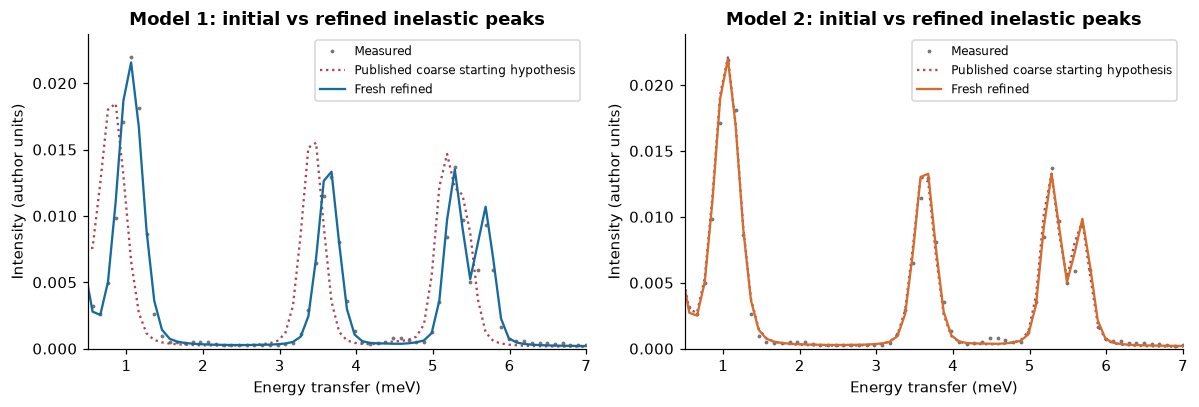

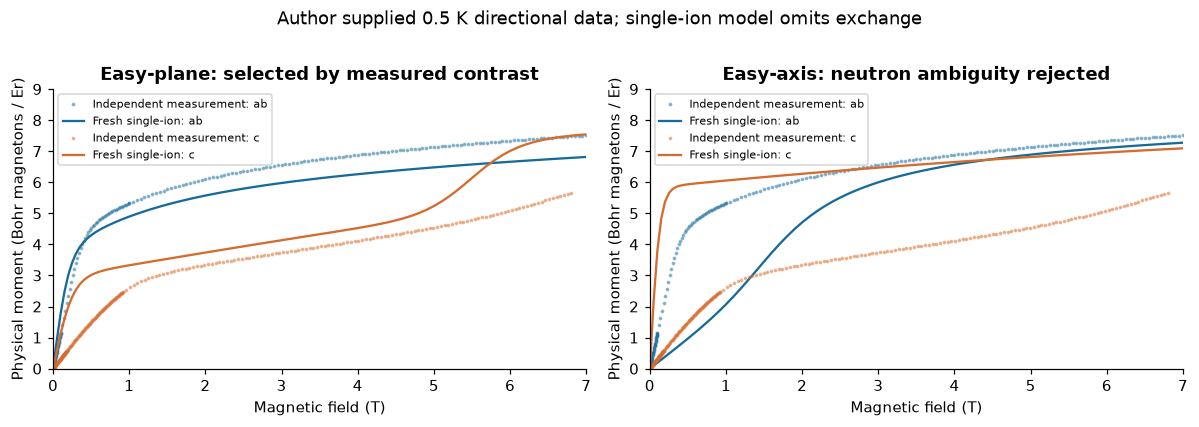

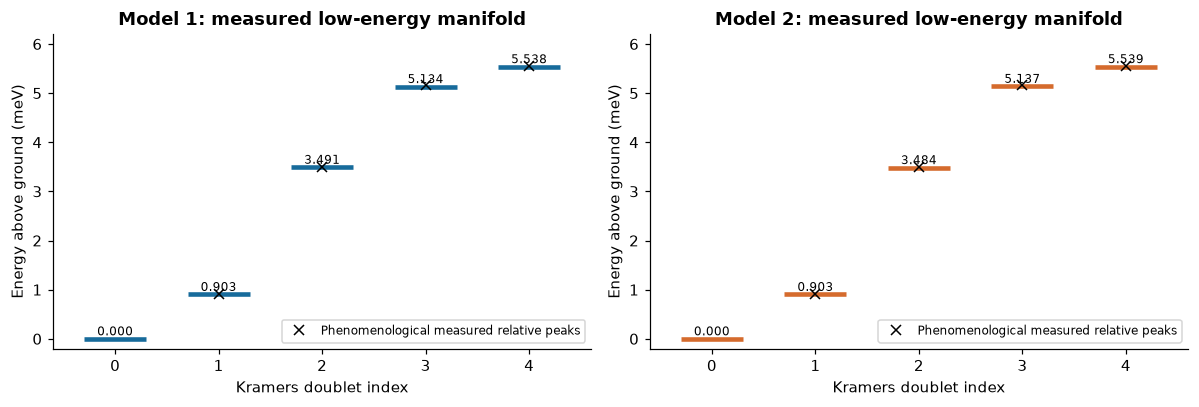

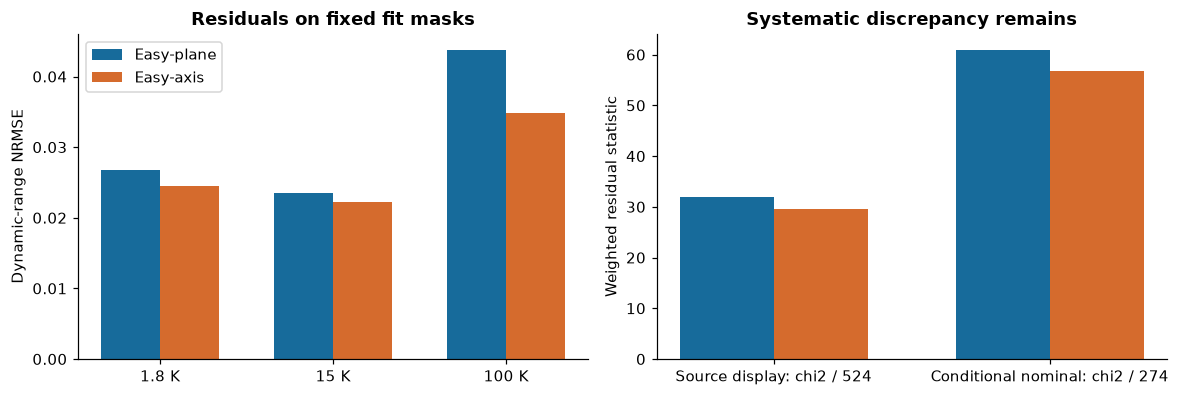

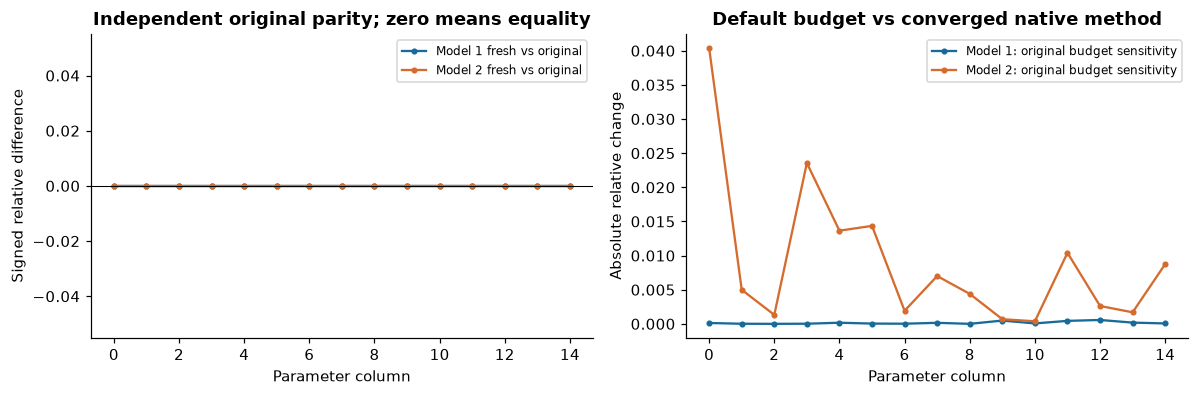

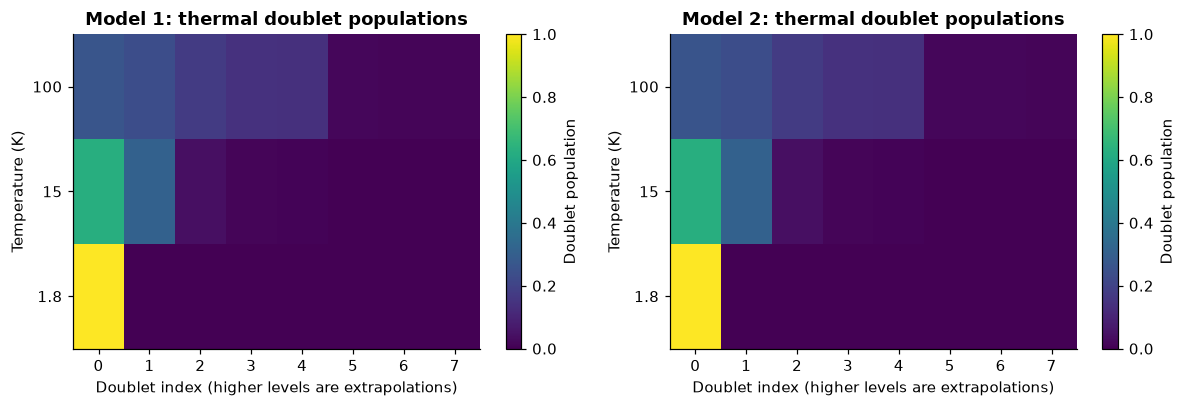

Fresh review figure count: 10


In [3]:
upstream=dict(np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False))
fresh_gtensors=np.stack([gtensor(q[:6]) for q in prediction['reconstruction'][0]])
print('Fresh ground-doublet g tensors (dimensionless):',fresh_gtensors)
print('Original current-code g tensors:',upstream['gtensors'])
print('Physical axis g values (row norms):',np.linalg.norm(fresh_gtensors,axis=2))
print('g tensor max absolute upstream difference:',np.max(abs(fresh_gtensors-upstream['gtensors'])))
result_metrics=metrics(prediction,data)
print(json.dumps(result_metrics,indent=2))
print('All statistics use the fixed mask. chi2/274 is conditional nominal DOF with fitted widths held fixed;')
print('same-data width-estimation uncertainty/correlations are not propagated. Source display uses chi2/524.')
plots=figures(prediction,diagnostics,data,upstream)
for fig in plots:
    display(fig)
    plt.close(fig)
print('Fresh review figure count:',len(plots))


In [4]:
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
judged=subprocess.run(command,cwd=ROOT,capture_output=True,text=True)
print(judged.stdout)
print(judged.stderr)
assert judged.returncode==0, 'Fresh complete reconstruction failed standalone evaluation'
report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
print(json.dumps(report,indent=2))
assert report['passed']




{
  "status": "pass",
  "passed": true,
  "metrics": {
    "model0_parameter_relative_max": 0.0,
    "model0_spectrum_nrmse": 0.0,
    "model0_physical_domain": 1.0,
    "model0_forward_consistency": 2.258624605190027e-14,
    "model0_excitation_error_meV": 0.02223039723402742,
    "model0_anisotropy_order": 1.0,
    "model0_temperature0_observed_nrmse": 0.02680480098625021,
    "model0_temperature0_observed_ncc": 0.9962300920147804,
    "model0_temperature1_observed_nrmse": 0.02354987818332444,
    "model0_temperature1_observed_ncc": 0.9950981201951515,
    "model0_temperature2_observed_nrmse": 0.0438087033406866,
    "model0_temperature2_observed_ncc": 0.9935633708165444,
    "model1_parameter_relative_max": 0.0,
    "model1_spectrum_nrmse": 0.0,
    "model1_physical_domain": 1.0,
    "model1_forward_consistency": 3.432901002976664e-14,
    "model1_excitation_error_meV": 0.020985631044325714,
    "model1_anisotropy_order": 1.0,
    "model1_temperature0_observed_nrmse": 0.0244867991

## 6. Conclusion
The active measured-data inversion recovers both neutron-consistent conditional Hamiltonians, their three-temperature broadenings/backgrounds, common scale/offset/axis expansion, and same-data width regression. It materially improves the published coarse starting hypotheses. Powder spectra alone leave competing anisotropy branches; positive physical longitudinal magnetization is minus the source's g-times-J expectation, and the independent measured basal-plane contrast selects the easy-plane branch.

Agreement with the independently rerun method is reproducibility evidence, not known microscopic truth. Conditional nominal chi-square per DOF remains about 57–61 because the empirical background/response misses systematic structure and fitted width uncertainty is not propagated. The single-ion magnetic model omits exchange and does not exactly match every amplitude. High unobserved doublets are conditional extrapolations. A simultaneous sign flip of B43/B63 is a transverse-axis gauge, not a different measured solution; rows are not freely exchanged. All conclusions are restricted to the supplied observations and selected published/current-code variant.